# Retrieval

BM25 and six embedding models on product titles and on full product text. Runs from `scripts/run_retrieval.py` on an RTX 4070.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D

from rlt.data import load
from rlt.metrics import gains, holm, ndcg_at, paired_test, rcap_at
from rlt.retrieve import rrf

products, queries, labels = load()
runs = {f.stem: np.load(f) for f in sorted(Path("../runs").glob("*.npz"))}

In [2]:
metrics = {
    "nDCG@10": lambda g, q: ndcg_at(g, q, labels, 10),
    "Rcap@100 Exact": lambda g, q: rcap_at(g, q, labels, 100, 2),
    "Rcap@100 Exact + Partial": lambda g, q: rcap_at(g, q, labels, 100, 1),
    "Rcap@1000 Exact + Partial": lambda g, q: rcap_at(g, q, labels, 1000, 1),
}
per_query = {}
for name, run in runs.items():
    ranked_gains = gains(run["ids"], run["query_ids"], labels)
    per_query[name] = {m: f(ranked_gains, run["query_ids"]) for m, f in metrics.items()}

## Results

Mean over queries. Rcap@k = relevant products in the top k / min(relevant products, k). Queries without relevant products are left out (101 for Exact, 1 for Exact + Partial).

We pick the retriever on Rcap@100 Exact + Partial. The median query has 170 Exact + Partial products, so the cut usually falls well past position 10, which is all nDCG@10 measures. Exact-only metrics also leave out 101 queries. nDCG@10 is used if two runs tie.

In [3]:
results = pd.DataFrame(
    {name: {m: np.nanmean(v) for m, v in values.items()} for name, values in per_query.items()}
).T
results["minutes"] = [float(runs[name]["seconds"]) / 60 for name in results.index]
results = results.sort_values("Rcap@100 Exact + Partial", ascending=False)
Path("../results").mkdir(exist_ok=True)
results.round(4).to_csv("../results/retrieval.csv")
results.round(3)

,nDCG@10,Rcap@100 Exact,Rcap@100 Exact + Partial,Rcap@1000 Exact + Partial,minutes
arctic-m_title,0.769,0.684,0.743,0.885,0.212
arctic-l_title,0.758,0.684,0.741,0.870,0.289
qwen3-4b_full,0.771,0.761,0.740,0.892,58.614
qwen3-4b_title,0.760,0.697,0.736,0.878,2.285
pplx-4b_full,0.763,0.739,0.732,0.883,59.864
arctic-m_full,0.775,0.752,0.731,0.887,2.232
arctic-l_full,0.772,0.744,0.730,0.875,4.668
bm25_title,0.706,0.645,0.716,0.851,0.025
qwen3-0.6b_title,0.738,0.640,0.697,0.830,0.727
qwen3-0.6b_full,0.732,0.682,0.687,0.842,12.308


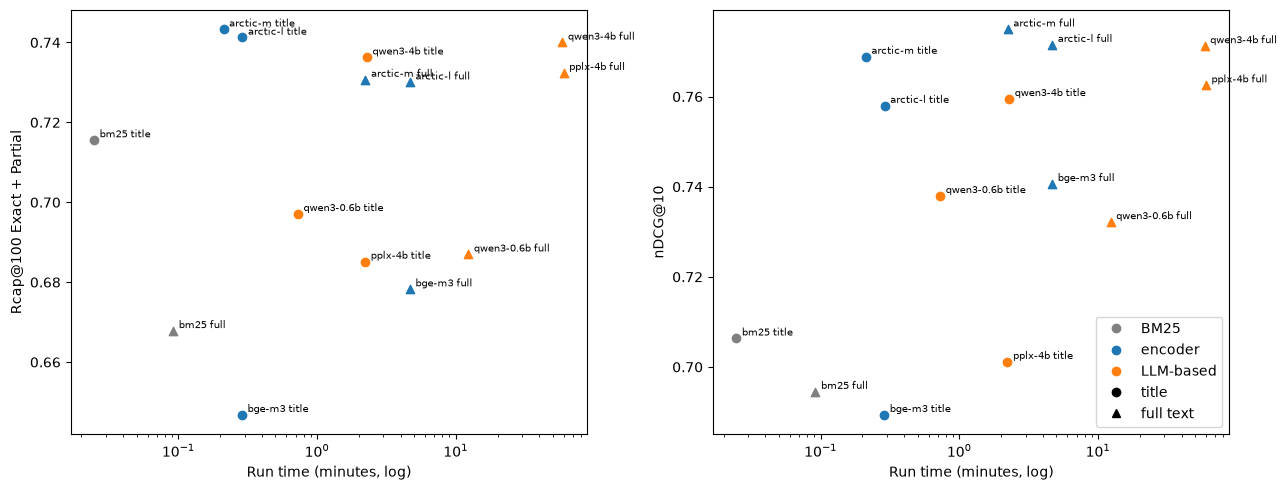

In [4]:
kinds = {
    "bm25": "BM25",
    "arctic-m": "encoder",
    "arctic-l": "encoder",
    "bge-m3": "encoder",
    "qwen3-0.6b": "LLM-based",
    "qwen3-4b": "LLM-based",
    "pplx-4b": "LLM-based",
}
colours = {"BM25": "grey", "encoder": "tab:blue", "LLM-based": "tab:orange"}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, metric in zip(axes, ["Rcap@100 Exact + Partial", "nDCG@10"], strict=True):
    for name, row in results.iterrows():
        model, text = name.rsplit("_", 1)
        marker = "o" if text == "title" else "^"
        ax.scatter(row["minutes"], row[metric], color=colours[kinds[model]], marker=marker)
        ax.annotate(f"{model} {text}", (row["minutes"], row[metric]), xytext=(4, 2),
                    textcoords="offset points", fontsize=7)
    ax.set(xscale="log", xlabel="Run time (minutes, log)", ylabel=metric)
handles = [Line2D([], [], color=c, marker="o", linestyle="", label=k) for k, c in colours.items()]
handles += [
    Line2D([], [], color="black", marker="o", linestyle="", label="title"),
    Line2D([], [], color="black", marker="^", linestyle="", label="full text"),
]
axes[1].legend(handles=handles, loc="lower right")
fig.tight_layout()
plt.show()

## Paired tests against arctic-m title

arctic-m title has the highest Rcap@100 Exact + Partial and is the fastest dense run. We compare it with every run within 0.015, using a paired permutation test over queries (10,000 sign flips) and Holm correction for the six tests per metric.

In [5]:
reference = "arctic-m_title"
candidates = [
    "arctic-l_title",
    "qwen3-4b_full",
    "qwen3-4b_title",
    "pplx-4b_full",
    "arctic-m_full",
    "arctic-l_full",
]
rows = []
for metric in ["Rcap@100 Exact + Partial", "nDCG@10"]:
    p = [paired_test(per_query[c][metric], per_query[reference][metric]) for c in candidates]
    for c, p_value, p_holm in zip(candidates, p, holm(p), strict=True):
        difference = np.nanmean(per_query[c][metric] - per_query[reference][metric])
        rows.append({"metric": metric, "run": c, "difference": difference, "p": p_value,
                     "p (Holm)": p_holm})
tests = pd.DataFrame(rows)
tests["significant"] = tests["p (Holm)"] < 0.05
tests.round(4)

,metric,run,difference,p,p (Holm),significant
0,Rcap@100 Exact + Partial,arctic-l_title,-0.0021,0.5357,1.0000,False
1,Rcap@100 Exact + Partial,qwen3-4b_full,-0.0033,0.6521,1.0000,False
2,Rcap@100 Exact + Partial,qwen3-4b_title,-0.0070,0.2423,0.7268,False
3,Rcap@100 Exact + Partial,pplx-4b_full,-0.0109,0.1273,0.5091,False
4,Rcap@100 Exact + Partial,arctic-m_full,-0.0126,0.0364,0.2184,False
5,Rcap@100 Exact + Partial,arctic-l_full,-0.0133,0.0409,0.2184,False
6,nDCG@10,arctic-l_title,-0.0109,0.0184,0.1104,False
7,nDCG@10,qwen3-4b_full,0.0024,0.7644,1.0000,False
8,nDCG@10,qwen3-4b_title,-0.0094,0.1448,0.7239,False
9,nDCG@10,pplx-4b_full,-0.0063,0.3792,1.0000,False


No run is significantly different from arctic-m title. It is also the fastest dense run: 13 s for the whole catalogue, against 2 to 60 min for the others. We use arctic-m title.

## arctic-m title + BM25 title (RRF)

Reciprocal rank fusion with k = 60. BM25 products with score 0 match no query word and are left out.

In [6]:
fused_ids, fused_scores = rrf(
    [zip(runs[n]["ids"], runs[n]["scores"], strict=True) for n in [reference, "bm25_title"]]
)
query_ids = runs[reference]["query_ids"]
fused_gains = gains(fused_ids, query_ids, labels)
fused = {m: f(fused_gains, query_ids) for m, f in metrics.items()}
pd.DataFrame(
    [
        {
            "metric": m,
            "arctic-m title": np.nanmean(per_query[reference][m]),
            "RRF": np.nanmean(fused[m]),
            "p": paired_test(fused[m], per_query[reference][m]),
        }
        for m in ["Rcap@100 Exact + Partial", "nDCG@10"]
    ]
).round(4)

,metric,arctic-m title,RRF,p
0,Rcap@100 Exact + Partial,0.7433,0.7539,0.0323
1,nDCG@10,0.7689,0.7654,0.5684


RRF is significantly better on Rcap@100 Exact + Partial (+0.011, p = 0.03) and no different on nDCG@10. We use arctic-m title + BM25 title with RRF.